# 05 · Optimización: ¿dónde va una nueva línea de teleférico?

**Pregunta:** ¿dónde ubicar k nuevas estaciones para cubrir a la mayor cantidad de población hoy a más de
15 minutos a pie, qué línea las conecta con la red y cuánto rinde por km de cable?

**Método** (`teleferico.optimize`; corre en el pipeline con `--pasos optimizacion`):
1. **Demanda:** hexágonos H3 r9 con su población **no cubierta** (a > 15 min con pendiente, notebook 03).
2. **Zonas sin cobertura (DBSCAN)** sobre los hexágonos densos no cubiertos, con la población como
   `sample_weight`. Solo se reportan las zonas que persisten en la mayoría de 9 combinaciones de
   parámetros.
3. **Candidatos:** centros de hexágonos en las zonas sin cobertura y hasta 2 anillos alrededor, con pendiente del
   terreno ≤ 30 %.
4. **Tiempo a pie** demanda → candidato con el mismo grafo y la misma función de Tobler direccional.
5. **MCLP** (máxima cobertura) y **p-mediana** (mínimo tiempo total) con `spopt`, para k = 3…10.
6. **Trazado:** búsqueda en haz de una línea que sale de una estación existente, con vanos de 700-2.500 m
   y giros ≤ 60° en las estaciones, que maximiza la población nueva por km de cable.
7. **Impacto:** cobertura recalculada por manzano y pasajeros/año estimados con el modelo del notebook 04.

> **Escenario guiado por datos, no diseño de ingeniería:** no se evalúan derechos de vía, torres, costos ni
> factibilidad política (ver `docs/plan.md` §8).

In [1]:
import json

import geopandas as gpd
import h3
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

from teleferico import access as ac
from teleferico import demand_model as dm
from teleferico import optimize as op
from teleferico import viz
from teleferico.config import CRS_METRIC, CRS_WGS84, PROCESSED

viz.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

D = op.OUT_DIR
acc = pd.read_parquet(ac.OUT_DIR / "manzanos_acceso.parquet")
dem_h = pd.read_parquet(D / "demanda_h3.parquet")
bol = pd.read_parquet(D / "bolsones.parquet")
cand = gpd.read_parquet(D / "candidatos.parquet").to_crs(CRS_METRIC)
curva = pd.read_parquet(D / "curva_mclp.parquet")
elegidos = pd.read_parquet(D / "mclp_elegidos.parquet")
pmed = pd.read_parquet(D / "pmediana.parquet")
lineas_haz = pd.read_parquet(D / "lineas_haz.parquet")
linea = gpd.read_parquet(D / "linea_propuesta.parquet").to_crs(CRS_METRIC)
nuevas = gpd.read_parquet(D / "estaciones_propuestas.parquet").to_crs(CRS_METRIC)
m_prop = pd.read_parquet(D / "manzanos_propuesta.parquet")
resumen = json.loads((D / "resumen_propuesta.json").read_text(encoding="utf-8"))
Ts = dict(np.load(op.MATRIZ_PATH))

lim = gpd.read_parquet(PROCESSED / "limites.parquet").to_crs(CRS_METRIC)
mun = lim.query("nivel == 'municipio'")
est = gpd.read_parquet(PROCESSED / "red" / "estaciones.parquet").to_crs(CRS_METRIC)
lineas = gpd.read_parquet(PROCESSED / "red" / "lineas.parquet").to_crs(CRS_METRIC)

def hexagonos(df):
    return gpd.GeoDataFrame(df, geometry=ac.hexagonos(df["h3"]).values, crs=CRS_WGS84).to_crs(CRS_METRIC)

dem = hexagonos(dem_h)
hx_todos = hexagonos(pd.read_parquet(ac.OUT_DIR / "h3_acceso_r9.parquet"))
bounds = hx_todos.total_bounds + np.array([-500, -500, 500, 500])
w = dem_h["personas"].to_numpy()
print(f"{len(dem):,} hexágonos con población no cubierta · {w.sum():,.0f} personas · "
      f"{len(bol)} bolsones robustos · {len(cand):,} candidatos")

2,780 hexágonos con población no cubierta · 1,227,666 personas · 16 bolsones robustos · 957 candidatos


## 1. Zonas sin cobertura (DBSCAN)

### Calibración de `eps`

Distancia al 6.º vecino más cercano entre los hexágonos densos no cubiertos. En una grilla H3 r9 los
centros vecinos están a ~350 m. El codo de la curva indica la escala a la que los hexágonos dejan de ser
contiguos.

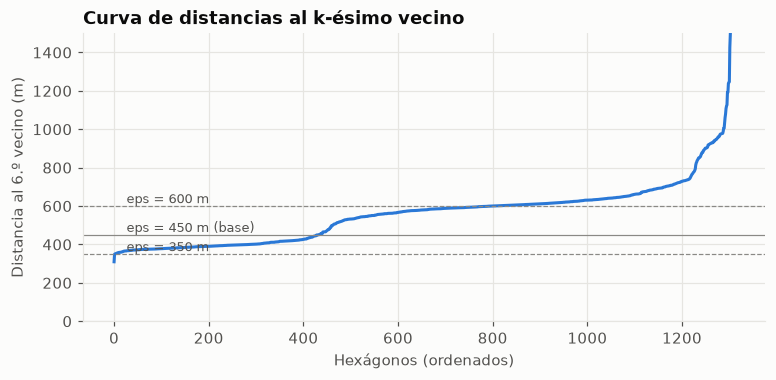

Percentiles de la distancia al 6.º vecino (m): [409. 580. 626. 708.]


In [2]:
kd = op.distancia_k_vecino(op.demanda_no_cubierta(acc))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(np.arange(len(kd)), kd, color=viz.ACENTO)
for e in op.GRILLA_EPS:
    ax.axhline(e, color=viz.TINTA_3, lw=0.8, ls="--" if e != op.EPS_M else "-")
    ax.text(len(kd) * 0.02, e + 15, f"eps = {e} m" + (" (base)" if e == op.EPS_M else ""), fontsize=8.5, color=viz.TINTA_2)
ax.set_ylim(0, 1500)
ax.set_xlabel("Hexágonos (ordenados)")
ax.set_ylabel("Distancia al 6.º vecino (m)")
ax.set_title("Curva de distancias al k-ésimo vecino")
viz.guardar(fig, "05_k_distancia")
plt.show()
print("Percentiles de la distancia al 6.º vecino (m):", np.percentile(kd, [25, 50, 75, 90]).round(0))

### Robustez: número de zonas sin cobertura y población según los parámetros

In [3]:
dem_full = op.demanda_no_cubierta(acc)
filas = []
for e in op.GRILLA_EPS:
    for pct in op.GRILLA_PCT:
        b = op.dbscan(dem_full, e, op.POB_NUCLEO, pct)
        filas.append({"eps_m": e, "percentil_densidad": pct, "bolsones": int(b.max() + 1),
                      "personas_en_bolsones": dem_full.loc[b >= 0, "personas"].sum()})
rob = pd.DataFrame(filas)
rob.pivot(index="eps_m", columns="percentil_densidad", values="personas_en_bolsones").style.format(viz.fmt_int)

percentil_densidad,40,50,60
eps_m,,,
350,143.304,140.620,138.941
450,574.435,561.380,529.389
600,811.896,737.253,652.191


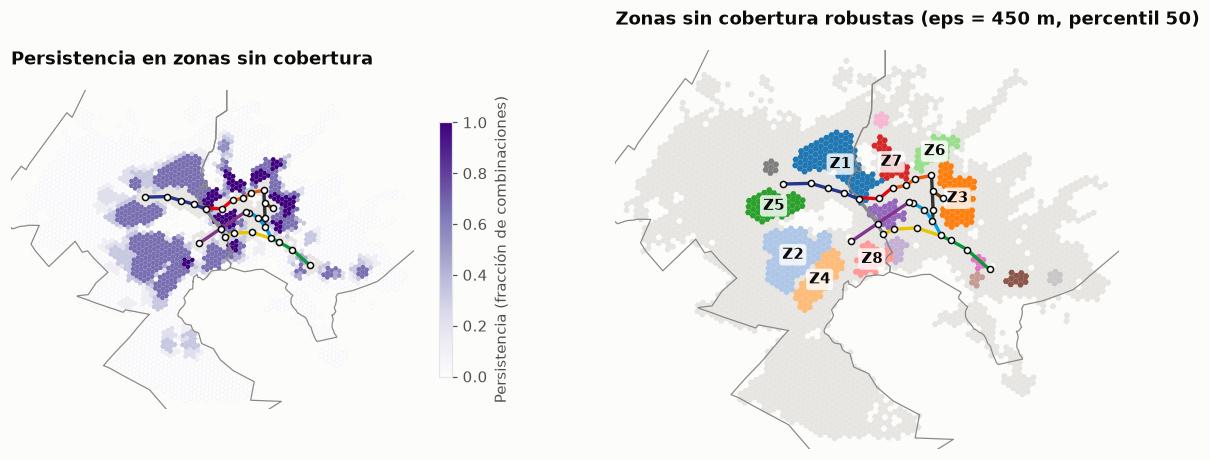

,municipio,zona,personas_no_cubiertas,area_km2,densidad_no_cubierta_hab_km2,t_actual_min,iv,persistencia
id,,,,,,,,
Z1,El Alto,El Alto,102.723,10.8,9.468,26,0.57,0.73
Z2,El Alto,El Alto,96.560,11.0,8.815,52,0.48,0.66
Z3,La Paz,San Antonio,68.560,6.4,10.670,29,0.42,0.83
Z4,El Alto,El Alto,51.093,5.8,8.819,42,0.46,0.71
Z5,El Alto,El Alto,46.940,5.3,8.913,27,0.52,0.66
Z6,La Paz,Periférica,41.363,3.7,11.220,29,0.48,0.85
Z7,La Paz,Periférica,33.431,2.9,11.335,31,0.44,0.87
Z8,El Alto,El Alto,33.131,3.4,9.829,24,0.45,0.66
Z9,La Paz,Cotahuma,31.261,2.5,12.366,19,0.51,0.94


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 6))
ax = axs[0]
hx_todos.plot(ax=ax, color=viz.GRILLA, linewidth=0)
dem.plot(ax=ax, column="persistencia", cmap="Purples", vmin=0, vmax=1, linewidth=0, legend=True,
         legend_kwds={"shrink": 0.5, "label": "Persistencia (fracción de combinaciones)"})
viz.mapa_base(ax, mun, lineas, est, bounds)
ax.set_title("Persistencia en zonas sin cobertura")

ax = axs[1]
hx_todos.plot(ax=ax, color=viz.GRILLA, linewidth=0)
b = dem[dem["bolson"] >= 0]
paleta = plt.get_cmap("tab20")
orden = {k: i for i, k in enumerate(bol["bolson"])}
for k, g in b.groupby("bolson"):
    g.plot(ax=ax, color=paleta(orden[k] % 20), linewidth=0)
viz.mapa_base(ax, mun, lineas, est, bounds)
for i, r in bol.head(8).iterrows():
    p = gpd.GeoSeries(gpd.points_from_xy([r["lon"]], [r["lat"]]), crs=CRS_WGS84).to_crs(CRS_METRIC).iat[0]
    ax.annotate(f"Z{i + 1}", (p.x, p.y), fontsize=10, fontweight="bold", color=viz.TINTA,
                ha="center", va="center", bbox={"boxstyle": "round,pad=0.2", "fc": "white", "ec": "none", "alpha": 0.8})
ax.set_title(f"Zonas sin cobertura robustas (eps = {op.EPS_M} m, percentil {op.PCT_DENSIDAD})")
viz.guardar(fig, "05_bolsones")
plt.show()

tabla_b = bol.assign(id=[f"Z{i + 1}" for i in range(len(bol))]).set_index("id")[
    ["municipio", "zona", "personas_no_cubiertas", "area_km2", "densidad_no_cubierta_hab_km2",
     "t_actual_min", "iv", "persistencia"]]
tabla_b.style.format({"personas_no_cubiertas": viz.fmt_int, "area_km2": "{:.1f}",
                      "densidad_no_cubierta_hab_km2": viz.fmt_int, "t_actual_min": "{:.0f}",
                      "iv": "{:.2f}", "persistencia": "{:.2f}"})

**Lectura:**
- La distancia al 6.º vecino tiene mediana de ~580 m. Con `eps` = 350 m casi nada se agrupa (140 mil
  personas); con 450-600 m aparecen las zonas sin cobertura (530-810 mil). Se elige **450 m**: une hexágonos contiguos
  sin fusionar zonas separadas por quebradas o por la autopista.
- Con eps = 450 m, el resultado es estable frente al umbral de densidad (±4 % de población entre los
  percentiles 40 y 60).
  Las **16 zonas sin cobertura** reportadas persisten en al menos la mitad de las 9 combinaciones; las de las laderas
  de La Paz son los más estables (persistencia de 0,8-0,9).
- **Hipótesis 2, confirmada:** las mayores zonas sin cobertura están en **El Alto**: Z1 al norte de 16 de Julio (103 mil
  personas no cubiertas), Z2 al sur (97 mil, a 52 min de una estación hoy), Z4 y Z5. En La Paz, **Z3 en San
  Antonio** (69 mil) y las laderas de Periférica (Z6 y Z7) y Cotahuma (Z9). Las zonas sin cobertura tienen densidades
  de 8-13 mil hab/km², y los 10 mayores, un índice de vulnerabilidad medio de 0,42-0,57.

## 2. MCLP: ¿cuánta población se cubre con k estaciones nuevas?

Las estaciones del MCLP son libres: pueden quedar dispersas por toda la ciudad. Es la **cota superior** de
lo que lograrían k estaciones, sin la restricción de formar una línea.

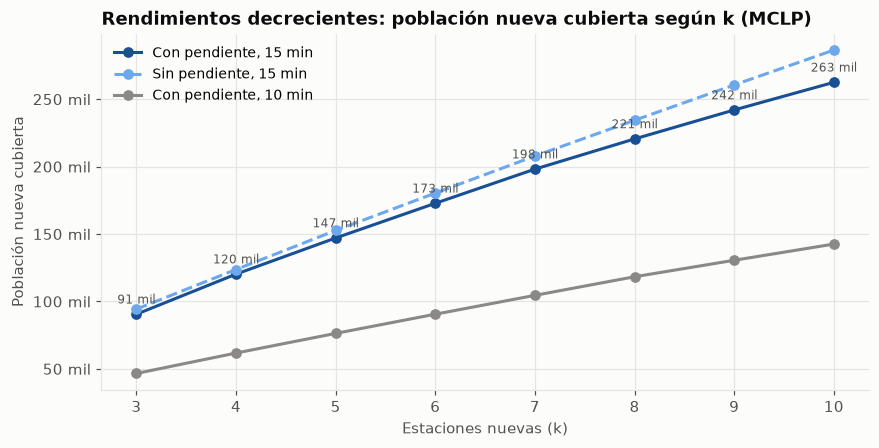

k,3,4,5,6,7,8,9,10
personas,90.514,120.258,147.067,172.792,198.136,220.530,242.014,262.511
marginal,90.514,29.744,26.809,25.725,25.344,22.394,21.484,20.497
por_estacion,30.171,30.064,29.413,28.799,28.305,27.566,26.890,26.251


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.2))
estilos = {("pendiente", 15): ("Con pendiente, 15 min", viz.SECUENCIAL[5], "-"),
           ("plana", 15): ("Sin pendiente, 15 min", viz.SECUENCIAL[2], "--"),
           ("pendiente", 10): ("Con pendiente, 10 min", viz.TINTA_3, "-")}
for (v, u), (lab, col, ls) in estilos.items():
    c = curva[(curva["variante"] == v) & (curva["umbral"] == u)]
    ax.plot(c["k"], c["personas"], marker="o", color=col, ls=ls, label=lab)
c15 = curva[(curva["variante"] == "pendiente") & (curva["umbral"] == 15)].set_index("k")["personas"]
for k, v in c15.items():
    ax.annotate(viz.miles(v), (k, v), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8, color=viz.TINTA_2)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(viz.miles))
ax.set_xlabel("Estaciones nuevas (k)")
ax.set_ylabel("Población nueva cubierta")
ax.legend(fontsize=9)
ax.set_title("Rendimientos decrecientes: población nueva cubierta según k (MCLP)")
viz.guardar(fig, "05_curva_mclp")
plt.show()

marg = c15.diff().fillna(c15)
pd.DataFrame({"personas": c15, "marginal": marg, "por_estacion": c15 / c15.index}).T.style.format(viz.fmt_int)

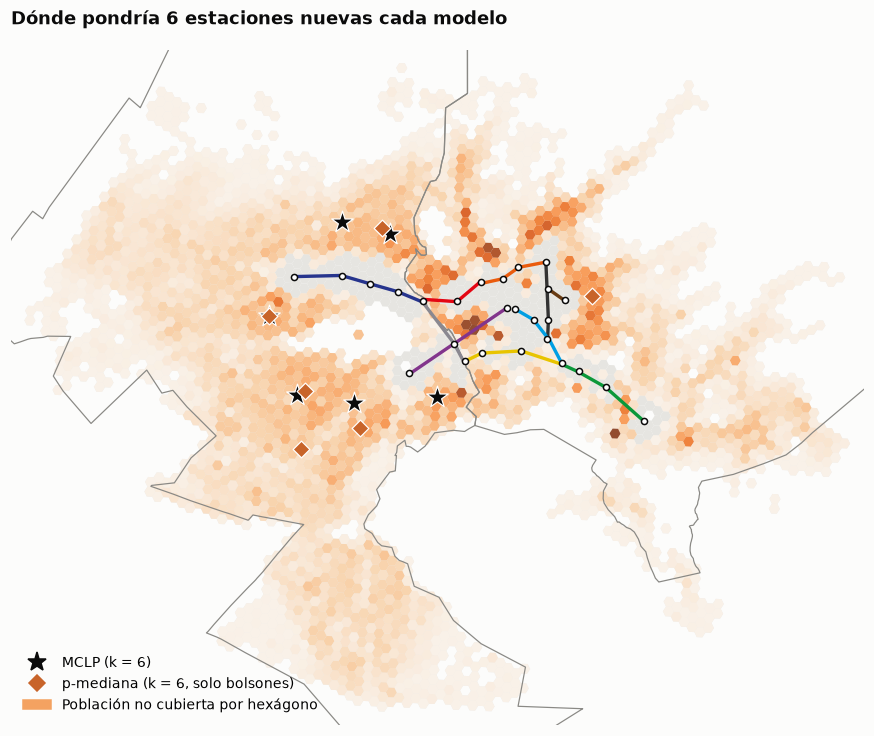

In [6]:
sel = elegidos[(elegidos["variante"] == "pendiente") & (elegidos["umbral"] == 15) & (elegidos["k"] == 6)]
pts = cand.set_index("h3").loc[sel["h3"]]
fig, ax = plt.subplots(figsize=(10, 8.5))
hx_todos.plot(ax=ax, color=viz.GRILLA, linewidth=0)
dem.plot(ax=ax, column="personas", cmap="Oranges", vmin=0, vmax=3000, linewidth=0, alpha=0.8)
viz.mapa_base(ax, mun, lineas, est, bounds)
pts.plot(ax=ax, marker="*", color=viz.TINTA, markersize=220, zorder=6, edgecolor="white", linewidth=0.8)
p6 = pmed.loc[pmed["k"] == 6, "h3"].iat[0]
cand.set_index("h3").loc[list(p6)].plot(ax=ax, marker="D", color="#c8642a", markersize=60, zorder=6,
                                         edgecolor="white", linewidth=0.8)
ax.legend(handles=[plt.Line2D([], [], marker="*", color=viz.TINTA, ls="", ms=13, label="MCLP (k = 6)"),
                   plt.Line2D([], [], marker="D", color="#c8642a", ls="", ms=7, label="p-mediana (k = 6, solo bolsones)"),
                   Patch(color="#f4a261", label="Población no cubierta por hexágono")],
          loc="lower left", fontsize=9)
ax.set_title("Dónde pondría 6 estaciones nuevas cada modelo")
viz.guardar(fig, "05_mclp_pmediana")
plt.show()

### p-mediana: tiempo medio de caminata en las zonas sin cobertura

In [7]:
pmed[["k", "t_medio_antes", "t_medio_despues", "personas_a_15"]].assign(
    reduccion_min=pmed["t_medio_antes"] - pmed["t_medio_despues"]).set_index("k").style.format(
    {"t_medio_antes": "{:.1f}", "t_medio_despues": "{:.1f}", "reduccion_min": "{:.1f}", "personas_a_15": viz.fmt_int})

,t_medio_antes,t_medio_despues,personas_a_15,reduccion_min
k,,,,
3,33.0,24.0,79.480,9.0
6,33.0,20.5,147.064,12.5
10,33.0,17.4,227.544,15.6


**Lectura:**
- **Rendimientos decrecientes suaves:** las primeras 3 estaciones cubren 90 mil personas (30 mil c/u); la
  décima agrega 20 mil. Con 10 estaciones libres se cubrirían 263 mil personas (21 % de la población hoy
  no cubierta).
- Sin pendiente, la curva sube apenas un 4-9 %: las zonas sin cobertura más grandes están en El Alto, que es plano.
  Con 10 minutos de umbral, la cobertura cae a la mitad (47-54 %).
- Con k = 6, el MCLP reparte estaciones entre el **norte (Z1)**, el oeste (Z5) y el **sur de El Alto
  (Z2/Z4)**, más una cerca de la línea Morada. La p-mediana, restringida a las zonas sin cobertura, coincide en El Alto y suma San Antonio
  (Z3). Baja el tiempo medio de caminata en las zonas sin cobertura de 33 a 20,5 min.
- Las estaciones libres del MCLP quedan **dispersas**: no forman una línea. Por eso el trazado se resuelve
  aparte, y el MCLP queda como cota superior.

## 3. Trazado de la línea

La búsqueda en haz arma, para cada número de estaciones nuevas, la línea con más población nueva por km.
El número de estaciones se elige con una regla de rendimiento marginal: se agregan estaciones mientras
cada una cubra al menos tantas personas por km como la red actual
(13.167 personas a ≤ 15 min por km de cable).

In [8]:
lh = lineas_haz.copy()
lh["marginal_por_km"] = lh["personas"].diff().fillna(lh["personas"]) / lh["km"].diff().fillna(lh["km"])
mclp_k = c15.reindex(lh["n_estaciones"]).to_numpy()
lh["eficiencia_vs_mclp_%"] = lh["personas"] / mclp_k * 100
lh.drop(columns="secuencia").set_index("n_estaciones").style.format(
    {"km": "{:.1f}", "personas": viz.fmt_int, "personas_por_km": viz.fmt_int, "marginal_por_km": viz.fmt_int,
     "eficiencia_vs_mclp_%": "{:.0f} %"}, na_rep="—")

,origen,km,personas,personas_por_km,marginal_por_km,eficiencia_vs_mclp_%
n_estaciones,,,,,,
1,16_de_julio,0.9,20.497,24.064,24.064,—
2,rio_seco,1.5,33.020,21.576,18.453,—
3,rio_seco,2.3,42.855,19.036,13.643,47 %
4,16_de_julio,3.7,67.541,18.129,16.745,56 %
5,16_de_julio,4.2,75.793,18.037,17.319,52 %
6,16_de_julio,5.1,90.721,17.638,15.854,53 %
7,16_de_julio,5.9,100.749,17.180,13.913,51 %
8,16_de_julio,6.6,106.082,16.109,7.399,48 %


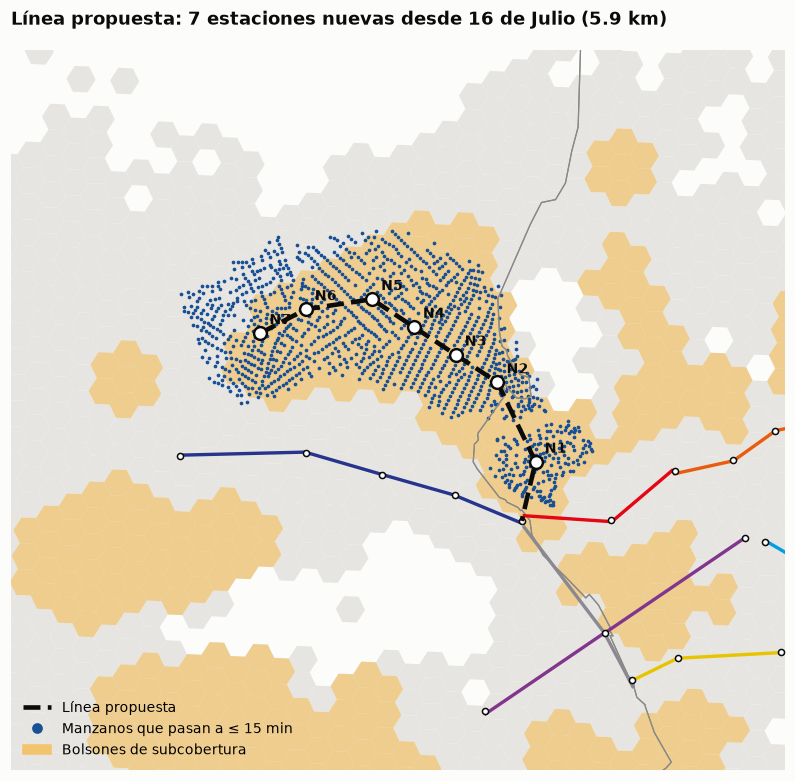

In [9]:
mz_nuevos = m_prop[(m_prop["t_despues"] <= 15) & ~(m_prop["t_antes"] <= 15)]
mz_xy = acc.set_index("codigo").loc[mz_nuevos["codigo"], ["lon", "lat"]]
nuevos_pts = gpd.GeoDataFrame(mz_nuevos, geometry=gpd.points_from_xy(mz_xy["lon"], mz_xy["lat"]),
                              crs=CRS_WGS84).to_crs(CRS_METRIC)

zoom = linea.buffer(3500).total_bounds
fig, ax = plt.subplots(figsize=(10, 8.5))
hx_todos.plot(ax=ax, color=viz.GRILLA, linewidth=0)
dem[dem["bolson"] >= 0].plot(ax=ax, color="#f2c46d", linewidth=0, alpha=0.7)
nuevos_pts.plot(ax=ax, color=viz.SECUENCIAL[5], markersize=2, zorder=3)
viz.mapa_base(ax, mun, lineas, est, zoom)
linea.plot(ax=ax, color=viz.TINTA, lw=3, ls="--", zorder=6)
nuevas.plot(ax=ax, color="white", edgecolor=viz.TINTA, markersize=70, linewidth=1.6, zorder=7)
for r in nuevas.itertuples():
    ax.annotate(r.id, (r.geometry.x, r.geometry.y), xytext=(6, 6), textcoords="offset points", fontsize=9,
                fontweight="bold", color=viz.TINTA)
ax.legend(handles=[plt.Line2D([], [], color=viz.TINTA, lw=3, ls="--", label="Línea propuesta"),
                   plt.Line2D([], [], marker="o", color=viz.SECUENCIAL[5], ls="", label="Manzanos que pasan a ≤ 15 min"),
                   Patch(color="#f2c46d", label="Bolsones de subcobertura")], loc="lower left", fontsize=9)
ax.set_title(f"Línea propuesta: {resumen['n_estaciones']} estaciones nuevas desde "
             f"{est.set_index('slug').loc[resumen['origen'], 'nombre']} ({resumen['km_cable']:.1f} km)")
viz.guardar(fig, "05_linea_propuesta")
plt.show()

**Lectura:**
- La mejor línea sale de **16 de Julio** (transbordo con las líneas Roja, Azul y Plateada) hacia el
  **noroeste**, a lo largo de la zona sin cobertura **Z1** (norte de El Alto). Tiene **7 estaciones nuevas en 5,9 km**,
  con vanos de 0,7-1,2 km, parecidos a los de la línea Azul.
- La regla marginal se detiene en 7: la 8.ª estación agregaría solo 7,4 mil personas por km, frente a las
  13,2 mil de la red actual.
- Cubre el **~50 % de lo que lograrían 7 estaciones libres** (MCLP). Es el costo de exigir que las
  estaciones formen una línea continua conectada a la red.
- La primera estación (N1) cae en el borde de la ladera de **Max Paredes** (La Paz) y cubre ~19 mil
  personas paceñas. Las otras 6 están en El Alto (77 mil personas).
- La evaluación por manzano (95 mil personas nuevas) da algo menos que la estimación por hexágonos de la
  búsqueda (101 mil): dentro de cada hexágono no todos los manzanos quedan a ≤ 15 min.

### Comparación con las líneas actuales: población a ≤ 15 min por km de cable

Para cada línea existente se cuenta la población a ≤ 15 min (con pendiente) de **alguna de sus estaciones**,
dividida por su longitud. Para la propuesta se usa solo la población **nueva**, la que hoy no tiene acceso,
un criterio más exigente.

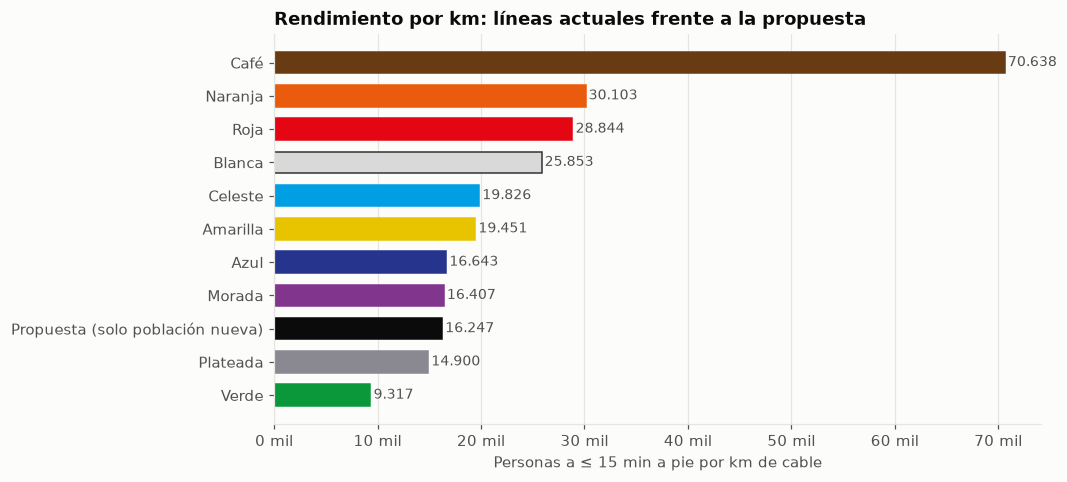

,km,personas_15,personas_por_km
linea,,,
Verde,3.7,34.754,9.317
Plateada,2.8,41.177,14.900
Propuesta (solo población nueva),5.9,95.276,16.247
Morada,4.4,72.106,16.407
Azul,5.0,82.630,16.643
Amarilla,3.8,72.961,19.451
Celeste,2.7,54.227,19.826
Blanca,2.9,74.829,25.853
Roja,2.4,68.836,28.844


In [10]:
nod, a = ac.nodos(), ac.aristas_tiempo()
T_est = ac.tiempos_por_estacion(a, nod, est, variantes=("pendiente",))
mz = ac.manzanos_centroides()
_, por_est = ac.acceso_manzanos(mz, nod, est, T_est)
pers = mz["personas"].to_numpy()
km_linea = lineas.groupby("linea")["longitud_m"].sum() / 1000
andenes = pd.read_parquet(PROCESSED / "red" / "andenes.parquet")
filas = []
for l, g in andenes.groupby("linea"):
    idx = est.index[est["slug"].isin(g["slug"])]
    cub = (por_est["pendiente"][idx] <= 15).any(axis=0)
    filas.append({"linea": l, "km": km_linea[l], "personas_15": pers[cub].sum()})
comp_l = pd.DataFrame(filas)
comp_l["personas_por_km"] = comp_l["personas_15"] / comp_l["km"]
comp_l = pd.concat([comp_l, pd.DataFrame([{"linea": "Propuesta (solo población nueva)", "km": resumen["km_cable"],
                                            "personas_15": resumen["personas_nuevas_15"],
                                            "personas_por_km": resumen["personas_nuevas_por_km"]}])])
comp_l = comp_l.sort_values("personas_por_km")

fig, ax = plt.subplots(figsize=(9, 4.6))
col = [viz.TINTA if l.startswith("Propuesta") else viz.COLOR_LINEA.get(l, viz.TINTA_3) for l in comp_l["linea"]]
borde = [viz.BORDE_LINEA.get(l, c) for l, c in zip(comp_l["linea"], col)]
ax.barh(comp_l["linea"], comp_l["personas_por_km"], color=col, edgecolor=borde, height=0.65)
for i, v in enumerate(comp_l["personas_por_km"]):
    ax.text(v + 300, i, viz.fmt_int(v), va="center", fontsize=9, color=viz.TINTA_2)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(viz.miles))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Personas a ≤ 15 min a pie por km de cable")
ax.set_title("Rendimiento por km: líneas actuales frente a la propuesta")
viz.guardar(fig, "05_rendimiento_lineas")
plt.show()
comp_l.set_index("linea").style.format({"km": "{:.1f}", "personas_15": viz.fmt_int, "personas_por_km": viz.fmt_int})

**Lectura:** la propuesta cubre **16,2 mil personas nuevas por km**, al nivel de la Azul (16,6 mil) y la
Morada (16,4 mil), y por encima de la Plateada y la Verde, que cuentan toda su población y no solo la nueva.
Las líneas cortas del centro (Café, Naranja, Roja) rinden más por km porque atraviesan las zonas más densas
y ya consolidadas.

## 4. Impacto: cobertura y pasajeros estimados

In [11]:
pas = op.pasajeros(nuevas)
tot = pas[dm.PRINCIPAL]["total"]
tot_ext = pas[dm.EXTENDIDO]["total"]
alto = acc[acc["municipio"] == "El Alto"]
pct_alto_antes = alto.loc[alto["t_pendiente_min"] <= 15, "personas"].sum() / alto["personas"].sum() * 100
impacto = pd.Series({
    "Estaciones nuevas": resumen["n_estaciones"],
    "Km de cable": round(resumen["km_cable"], 1),
    "Personas nuevas a ≤ 15 min": viz.fmt_int(resumen["personas_nuevas_15"]),
    "Personas nuevas a ≤ 10 min": viz.fmt_int(resumen["personas_nuevas_10"]),
    "…de ellas, vulnerables (Q4-Q5)": viz.fmt_int(resumen["personas_nuevas_vulnerables_15"]),
    "Personas nuevas por km": viz.fmt_int(resumen["personas_nuevas_por_km"]),
    "Cobertura a ≤ 15 min, total": f"{resumen['pct_15_antes']:.1f} % → {resumen['pct_15_despues']:.1f} %",
    "Cobertura a ≤ 15 min, El Alto": f"{pct_alto_antes:.1f} % → {resumen['pct_15_despues_el_alto']:.1f} %",
    "Abordajes/año (modelo principal), media [IC 90 %]":
        f"{tot['media'] / 1e6:.1f} M [{tot['p05'] / 1e6:.1f}-{tot['p95'] / 1e6:.1f} M]",
    "Abordajes/año (modelo extendido), media [IC 90 %]":
        f"{tot_ext['media'] / 1e6:.1f} M [{tot_ext['p05'] / 1e6:.1f}-{tot_ext['p95'] / 1e6:.1f} M]",
})
impacto.to_frame("valor")

,valor
Estaciones nuevas,7
Km de cable,5.9
Personas nuevas a ≤ 15 min,95.276
Personas nuevas a ≤ 10 min,59.251
"…de ellas, vulnerables (Q4-Q5)",59.687
Personas nuevas por km,16.247
"Cobertura a ≤ 15 min, total",24.9 % → 30.8 %
"Cobertura a ≤ 15 min, El Alto",12.9 % → 21.6 %
"Abordajes/año (modelo principal), media [IC 90 %]",9.4 M [5.7-13.9 M]
"Abordajes/año (modelo extendido), media [IC 90 %]",8.7 M [5.3-12.9 M]


In [12]:
por_est = pd.DataFrame({i: v for i, v in pas[dm.EXTENDIDO]["por_estacion"].items()}).T
nuevas.drop(columns="geometry").set_index("id")[["pob_pendiente_10", "pob_pendiente_15"]].join(
    por_est.add_prefix("abordajes_")).style.format(viz.fmt_int)

,pob_pendiente_10,pob_pendiente_15,abordajes_media,abordajes_p05,abordajes_p50,abordajes_p95
id,,,,,,
N1,10.437,21.951,1.231.127,288.426,1.082.780,2.721.386
N2,10.803,21.040,1.223.904,300.254,1.078.469,2.686.089
N3,12.435,25.903,1.266.145,308.899,1.120.719,2.752.067
N4,11.697,29.261,1.263.480,300.397,1.100.055,2.756.042
N5,10.099,24.308,1.275.001,299.595,1.105.086,2.821.769
N6,10.550,24.454,1.249.168,301.830,1.099.180,2.677.718
N7,8.962,22.413,1.216.842,292.738,1.067.002,2.584.181


**Lectura:**
- **95 mil personas** pasan a vivir a ≤ 15 min a pie de una estación (59 mil a ≤ 10 min). La cobertura total
  sube de **24,9 % a 30,8 %** y la de **El Alto, de 12,9 % a 21,6 %**.
- **El 63 % de las personas nuevas cubiertas (60 mil) está en los quintiles más vulnerables (Q4-Q5)**: la
  línea también reduce la brecha de equidad del notebook 03.
- Abordajes estimados: **~9 M/año** (IC 90 %: 5-14 M), unos 1,2 M por estación. Es coherente con las
  estaciones internas de la línea Azul (0,8-2,7 M cada una). No incluye los abordajes adicionales en 16 de
  Julio (en la Azul ese andén suma 4,7 M), y **una parte de los abordajes vendría de otras estaciones**: no son
  todos viajeros nuevos.

## 5. Sensibilidad del trazado

¿La línea elegida cambia si se usa la caminata sin pendiente o el umbral de 10 minutos?

In [13]:
w_ = dem_h["personas"].to_numpy()
filas = []
for nombre, T, u in (("Con pendiente, 15 min (base)", Ts["pendiente"], 15),
                     ("Sin pendiente, 15 min", Ts["plana"], 15),
                     ("Con pendiente, 10 min", Ts["pendiente"], 10)):
    L = op.trazar_linea(cand, T, w_, est, umbral=u)
    f = L.set_index("n_estaciones").loc[resumen["n_estaciones"]]
    comun = len(set(cand["h3"].iloc[list(f["secuencia"])]) & set(nuevas["h3"]))
    filas.append({"escenario": nombre, "origen": f["origen"], "km": f["km"], "personas": f["personas"],
                  "estaciones en común con la base": f"{comun} de {resumen['n_estaciones']}"})
pd.DataFrame(filas).set_index("escenario").style.format({"km": "{:.1f}", "personas": viz.fmt_int})

,origen,km,personas,estaciones en común con la base
escenario,,,,
"Con pendiente, 15 min (base)",16_de_julio,5.9,100.749,7 de 7
"Sin pendiente, 15 min",16_de_julio,5.9,104.711,4 de 7
"Con pendiente, 10 min",16_de_julio,6.0,63.013,0 de 7


**Lectura:**
- El **corredor es robusto**: con caminata plana o con umbral de 10 min, la mejor línea también sale de 16 de
  Julio y recorre el norte de El Alto, con la misma longitud (5,9-6,0 km).
- Lo que cambia es la **ubicación exacta de las estaciones**: sin pendiente coinciden 4 de 7 y con 10 min
  ninguna (se acercan más entre sí para cubrir radios más cortos). La ubicación fina debe definirse con
  estudios de terreno, no con este modelo.

## 6. Contraste con el proyecto anunciado: extensión de la Línea Café a Pampahasi

El único proyecto de ampliación con financiamiento aprobado (crédito del BID, Ley N° 1759) es la
**extensión de la Línea Café desde Las Villas hasta Pampahasi (~1,2 km)**, en el macrodistrito San Antonio.
Se evalúa con el mismo método: una estación nueva en Pampahasi (punto de OSM, nodo 1740962925).

In [14]:
pampahasi = gpd.GeoDataFrame({"id": ["Pampahasi"], "h3": [None]},
                              geometry=gpd.points_from_xy([-68.1037712], [-16.4997213]), crs=CRS_WGS84).to_crs(CRS_METRIC)
m_pa, est_pa = op.evaluar(pampahasi, acc, a, nod, mz)
km_pa = est.set_index("slug").geometry["las_villas"].distance(pampahasi.geometry.iat[0]) / 1000
r_pa = op.resumen_propuesta(m_pa, km_pa)
pas_pa = op.pasajeros(est_pa)

contraste = pd.DataFrame({
    "Línea Café → Pampahasi (anunciada)": {
        "estaciones nuevas": 1, "km": km_pa, "personas nuevas a ≤ 15 min": r_pa["personas_nuevas_15"],
        "personas nuevas por km": r_pa["personas_nuevas_por_km"],
        "abordajes/año (extendido)": pas_pa[dm.EXTENDIDO]["total"]["media"]},
    "Línea propuesta (este análisis)": {
        "estaciones nuevas": resumen["n_estaciones"], "km": resumen["km_cable"],
        "personas nuevas a ≤ 15 min": resumen["personas_nuevas_15"],
        "personas nuevas por km": resumen["personas_nuevas_por_km"],
        "abordajes/año (extendido)": tot_ext["media"]},
}).T
contraste.style.format({"estaciones nuevas": "{:.0f}", "km": "{:.1f}", "personas nuevas a ≤ 15 min": viz.fmt_int,
                        "personas nuevas por km": viz.fmt_int, "abordajes/año (extendido)": lambda x: f"{x / 1e6:.2f} M"})

,estaciones nuevas,km,personas nuevas a ≤ 15 min,personas nuevas por km,abordajes/año (extendido)
Línea Café → Pampahasi (anunciada),1,1.2,18.261,14.792,1.20 M
Línea propuesta (este análisis),7,5.9,95.276,16.247,8.73 M


In [15]:
# ¿En qué bolsón cae Pampahasi y qué parte de él cubre?
nuevos_pa = m_pa[(m_pa["t_despues"] <= 15) & ~(m_pa["t_antes"] <= 15)]
h_pa = h3.latlng_to_cell(-16.4997213, -68.1037712, 9)
b_pa = dem_h.loc[dem_h["h3"] == h_pa, "bolson"]
print("Hexágono de Pampahasi en bolsón:", int(b_pa.iat[0]) if len(b_pa) else "no (sin población no cubierta)")
print(f"Personas nuevas cubiertas por zona: {nuevos_pa.groupby('zona')['personas'].sum().round(0).to_dict()}")

Hexágono de Pampahasi en bolsón: 0
Personas nuevas cubiertas por zona: {'San Antonio': 18261}


**Lectura:**
- La extensión anunciada **apunta a una zona sin cobertura real**: Pampahasi está dentro de **Z3 (San Antonio)**, una de
  las zonas sin cobertura más grandes y persistentes de La Paz.
- Con 1 estación y 1,2 km cubre ~18 mil personas nuevas (**14,8 mil por km**), algo menos que la propuesta
  (16,2 mil/km), y estaría por encima del promedio de la red (13,2 mil/km).
- El modelo de demanda le asigna ~1,2 M de abordajes/año, pero con mucha incertidumbre: hoy Las Villas, la
  estación a la que se conecta, es una de las de menor demanda (0,35 M en 2025).
- Las dos intervenciones son complementarias: Pampahasi atiende una ladera de La Paz; la línea propuesta,
  la zona sin cobertura más grande de El Alto.

## 7. Conclusiones

| # | Hallazgo | Implicación |
|---|---|---|
| 1 | **H2 confirmada:** 16 zonas sin cobertura robustas con 561 mil personas no cubiertas. Los mayores están en El Alto (norte y sur de 16 de Julio) y en San Antonio (La Paz) | La expansión debe empezar por El Alto |
| 2 | MCLP: 3 estaciones libres cubren 90 mil personas y 10 cubren 263 mil. Los rendimientos decrecientes son suaves | Hay espacio para más de una intervención |
| 3 | **Propuesta: línea de 7 estaciones y 5,9 km desde 16 de Julio hacia el norte de El Alto** | Transbordo con Roja, Azul y Plateada en la estación de más demanda de la red |
| 4 | 95 mil personas nuevas a ≤ 15 min (16,2 mil/km, al nivel de Azul y Morada). Cobertura de El Alto: 12,9 % → 21,6 % | El mejor rendimiento por km disponible con una línea continua |
| 5 | 63 % de las personas nuevas cubiertas son vulnerables (Q4-Q5) | Argumento de equidad además de demanda |
| 6 | ~9 M de abordajes/año (IC 90 %: 5-14 M), sin contar los transbordos en 16 de Julio | Orden de magnitud similar al de la línea Azul (11,5 M en 2025) |
| 7 | El corredor se repite con caminata plana y con umbral de 10 min; la ubicación exacta de las estaciones no | Recomendar el **corredor**, no puntos exactos |
| 8 | La extensión anunciada a Pampahasi cae en la zona sin cobertura Z3 y rinde 14,8 mil personas/km | Validación independiente: el método identifica la misma prioridad que la planificación oficial en La Paz |

**Limitaciones:** escenario guiado por datos, sin costos, derechos de vía ni factibilidad de torres. La
caminata ignora el minibús, que es el principal alimentador. El modelo de demanda tiene n = 26 e intervalos
amplios. Los abordajes de la nueva línea no son todos viajeros nuevos.

## Anexo: exportación de datos para el sitio

In [16]:
(D / "pasajeros_propuesta.json").write_text(json.dumps(pas, ensure_ascii=False, indent=2), encoding="utf-8")
from teleferico.export_web import exportar_propuesta
exportar_propuesta()